# 02 · Safety Stock

**Safety stock is a plug number far too often — a flat "two weeks of stock" across
every product.** But the right buffer depends on how *variable* demand is, the
replenishment lead time, and the service level you target:

$$ \text{safety stock} = z_{\text{service}} \cdot \sigma_{\text{demand}} \cdot \sqrt{L + R} $$

This is the direct bridge from forecast error (the demand standard deviation σ) to an
inventory decision. A flat rule over-protects stable items and under-protects volatile
ones; setting the buffer by the distribution holds **less total inventory at a higher
service level** by moving it to where the uncertainty actually is.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from src.config import SETTINGS
from src.evaluation.cost_of_the_guess import safety_stock_inventory_gap
from src.evaluation.service_level import simulate_cycle_service_level
from src.inventory.safety_stock import flat_safety_stock, safety_stock
from src.outputs import save_figure, save_json

plt.rcParams["figure.figsize"] = (7, 4)
ss = SETTINGS.safety_stock
mean_demand = SETTINGS.demand.stationary.mean
ss

SafetyStockConfig(service_level=0.95, lead_time=4.0, review_period=1.0, flat_weeks=2.0)

## A range of products, from steady staple to volatile seasonal

Same average demand, very different volatility. The flat rule treats them identically.

In [2]:
sigmas = np.array([5.0, 8.0, 12.0, 20.0, 35.0, 50.0])
products = [f"P{i + 1}" for i in range(len(sigmas))]

inputs = {
    "mean_demand": mean_demand,
    "sigmas": sigmas,
    "lead_time": ss.lead_time,
    "review_period": ss.review_period,
    "service_level": ss.service_level,
    "flat_weeks": ss.flat_weeks,
}
save_json(inputs, "02_inputs")
inputs

{'mean_demand': 100.0,
 'sigmas': array([ 5.,  8., 12., 20., 35., 50.]),
 'lead_time': 4.0,
 'review_period': 1.0,
 'service_level': 0.95,
 'flat_weeks': 2.0}

## The formula delivers the service level it promises

Before trusting the formula, confirm it by simulation: draw lead-time demand, set the
reorder point from the safety-stock formula, and measure the fraction of cycles with no
stockout. The achieved service level should land on the target.

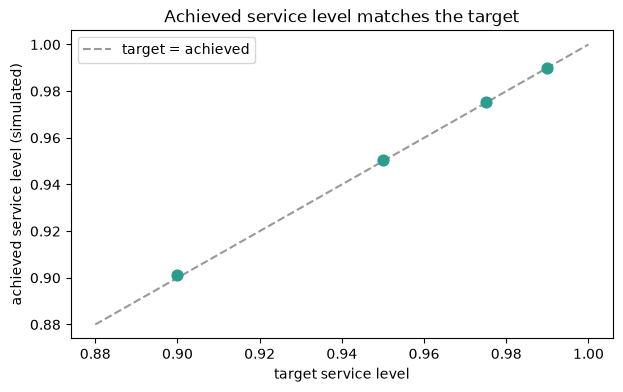

target 0.900 -> achieved 0.901
target 0.950 -> achieved 0.951
target 0.975 -> achieved 0.975
target 0.990 -> achieved 0.990


In [3]:
targets = [0.90, 0.95, 0.975, 0.99]
achieved = [
    simulate_cycle_service_level(mean_demand, 25.0, ss.lead_time, t, n_cycles=200_000, seed=1)
    for t in targets
]
save_json({"target": targets, "achieved": achieved}, "02_achieved_service_level")

fig, ax = plt.subplots()
ax.plot([0.88, 1.0], [0.88, 1.0], color="#999", linestyle="--", label="target = achieved")
ax.scatter(targets, achieved, color="#2a9d8f", s=60, zorder=3)
ax.set_xlabel("target service level")
ax.set_ylabel("achieved service level (simulated)")
ax.set_title("Achieved service level matches the target")
ax.legend()
save_figure(fig, "02_achieved_service_level")
plt.show()

for t, a in zip(targets, achieved):
    print(f"target {t:.3f} -> achieved {a:.3f}")

## A flat rule misplaces the buffer

Distribution-based safety stock per product versus the one-size-fits-all flat rule. The
flat rule sits far above the stable products (wasted capital) — and the volatile ones
need the buffer the distribution gives them.

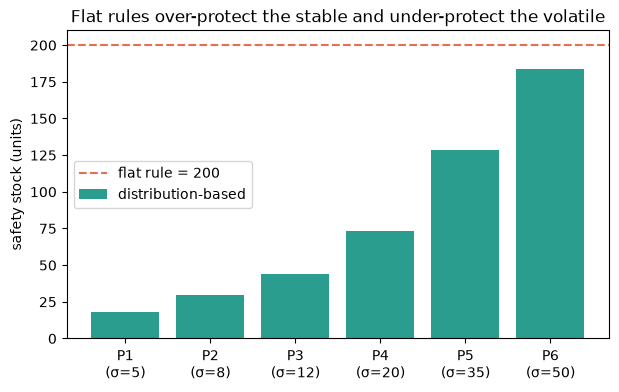

distribution-based total: 428
flat-rule total         : 1200
inventory saved         : 772


In [4]:
buffers = np.array([safety_stock(float(s), ss.lead_time, ss.service_level, ss.review_period) for s in sigmas])
flat = flat_safety_stock(mean_demand, ss.flat_weeks)
comparison = safety_stock_inventory_gap(sigmas, mean_demand, ss.lead_time, ss.service_level, ss.flat_weeks)
save_json({"products": products, "sigmas": sigmas, "distribution_based": buffers, "flat_rule": flat}, "02_buffers")
save_json(comparison, "02_comparison")

fig, ax = plt.subplots()
index = np.arange(len(sigmas))
ax.bar(index, buffers, color="#2a9d8f", label="distribution-based")
ax.axhline(flat, color="#e76f51", linestyle="--", label=f"flat rule = {flat:.0f}")
ax.set_xticks(index)
ax.set_xticklabels([f"{p}\n(σ={s:.0f})" for p, s in zip(products, sigmas)])
ax.set_ylabel("safety stock (units)")
ax.set_title("Flat rules over-protect the stable and under-protect the volatile")
ax.legend()
save_figure(fig, "02_safety_stock_by_product")
plt.show()

print(f"distribution-based total: {comparison.distribution_total:.0f}")
print(f"flat-rule total         : {comparison.flat_total:.0f}")
print(f"inventory saved         : {comparison.inventory_saved:.0f}")

## Safety stock is linear in σ and in the service-level multiplier

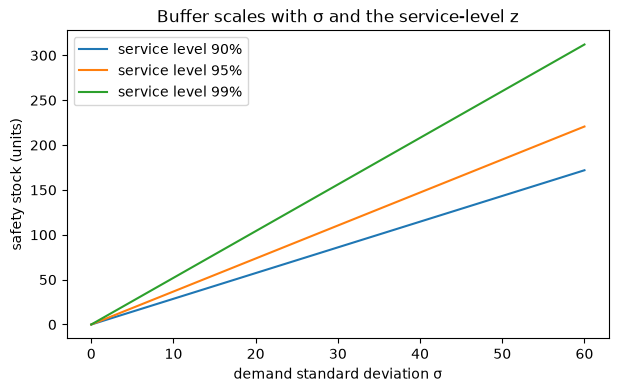

In [5]:
sigma_grid = np.linspace(0.0, 60.0, 100)
fig, ax = plt.subplots()
for service in [0.90, 0.95, 0.99]:
    curve = [safety_stock(float(s), ss.lead_time, service, ss.review_period) for s in sigma_grid]
    ax.plot(sigma_grid, curve, label=f"service level {service:.0%}")
ax.set_xlabel("demand standard deviation σ")
ax.set_ylabel("safety stock (units)")
ax.set_title("Buffer scales with σ and the service-level z")
ax.legend()
save_figure(fig, "02_buffer_vs_sigma")
plt.show()

## Takeaway

Safety stock is a **computable function of forecast error** (σ), lead time, and the
target service level — not a flat number. Setting it by the demand distribution moves
the buffer off the stable products that never needed it and onto the volatile ones that
did, so the network holds less total inventory at a higher service level. This connects
inventory directly to the forecasting and prediction-interval work: the distribution is
the input, the buffer is the decision.

In [6]:
takeaways = {
    "thesis": "Safety stock ties to demand sigma, lead time, and service level; flat rules waste inventory.",
    "distribution_total": round(comparison.distribution_total, 1),
    "flat_total": round(comparison.flat_total, 1),
    "inventory_saved": round(comparison.inventory_saved, 1),
    "service_level_check_max_error": round(max(abs(a - t) for t, a in zip(targets, achieved)), 4),
}
save_json(takeaways, "02_takeaways")
takeaways

{'thesis': 'Safety stock ties to demand sigma, lead time, and service level; flat rules waste inventory.',
 'distribution_total': 427.7,
 'flat_total': 1200.0,
 'inventory_saved': 772.3,
 'service_level_check_max_error': 0.0012}